<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №1
## по курсу «Технологии машинного обучения»

### Тема: Разведочный анализ данных (Exploratory Data Analysis)

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

**Дата выполнения:** 16.09.2026

---


## 1. Описание задания

**Цель работы:** изучение различных методов визуализации данных при проведении разведочного анализа (EDA).

**Задача:** построение основных графиков, входящих в этап разведочного анализа данных, для выбранного набора данных.

**План работы:**
1. Выбор набора данных (используется встроенный датасет `diabetes` из библиотеки `scikit-learn` — не содержит пропусков, имеет небольшой размер).
2. Текстовое описание выбранного набора данных.
3. Расчёт основных характеристик датасета.
4. Визуальное исследование датасета (гистограммы, boxplot, violinplot, scatterplot, pairplot и др.).
5. Анализ корреляции признаков (корреляционная матрица, тепловая карта, диаграммы рассеяния для наиболее коррелированных пар).

**Используемые библиотеки:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`.

Все графики и подписи к ним выполнены на русском языке.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.colors as mcolors
import seaborn as sns
from sklearn.datasets import load_diabetes

# Настройка шрифта для корректного отображения кириллицы на графиках
matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False

# Единая цветовая палитра отчёта: оттенки синего (признаки) и красного (целевая переменная)
BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

# Диаграмма для двух групп (пол пациента) и диаграмма рассеяния/линия регрессии
PALETTE_2 = [BLUE, RED]
# Диверсионная цветовая карта для тепловой карты корреляции и цветовой шкалы: синий - белый - красный
CMAP_DIVERGING = mcolors.LinearSegmentedColormap.from_list(
    "blue_white_red", [BLUE_DARK, "#F5F3F0", RED_DARK]
)

sns.set_theme(style="whitegrid", palette=PALETTE_2, font="DejaVu Sans")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42


## 2. Описание набора данных

Используется набор данных **Diabetes dataset** («Набор данных о диабете»), встроенный в `scikit-learn` (`sklearn.datasets.load_diabetes`).

Источник: https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html

Датасет содержит данные **442 пациентов** с диабетом. Для каждого пациента измерено **10 количественных признаков** (все признаки предварительно центрированы по среднему и отмасштабированы по стандартному отклонению, умноженному на корень из числа наблюдений):

| Признак | Описание |
|---|---|
| `age` | возраст пациента |
| `sex` | пол пациента |
| `bmi` | индекс массы тела (Body Mass Index) |
| `bp` | среднее артериальное давление (blood pressure) |
| `s1` (`tc`) | общий уровень холестерина в сыворотке крови |
| `s2` (`ldl`) | липопротеины низкой плотности |
| `s3` (`hdl`) | липопротеины высокой плотности |
| `s4` (`tch`) | отношение общего холестерина к HDL |
| `s5` (`ltg`) | логарифм уровня триглицеридов в сыворотке крови |
| `s6` (`glu`) | уровень сахара в крови |

**Целевая переменная (`target`)** — количественная оценка прогрессирования заболевания через год после начального измерения (чем выше значение, тем сильнее прогрессировало заболевание).

**Почему выбран этот датасет:** данные полностью числовые, не содержат пропущенных значений, имеют небольшой размер (442 наблюдения, 10 признаков), что удобно для демонстрации методов визуализации и корреляционного анализа, а тема (прогрессирование диабета) даёт содержательную интерпретацию результатов.


In [2]:
data = load_diabetes()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print(data.DESCR[:1500])


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [3]:
# Словарь с русскими подписями признаков — используется для оформления графиков
feature_names_ru = {
    "age": "Возраст",
    "sex": "Пол",
    "bmi": "Индекс массы тела (BMI)",
    "bp": "Артериальное давление",
    "s1": "Общий холестерин (s1)",
    "s2": "Липопротеины низкой плотности (s2)",
    "s3": "Липопротеины высокой плотности (s3)",
    "s4": "Отношение холестерина к HDL (s4)",
    "s5": "Логарифм триглицеридов (s5)",
    "s6": "Уровень сахара в крови (s6)",
    "target": "Прогрессирование диабета (целевая переменная)",
}

df.head(10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,138.0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,110.0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,310.0


## 3. Основные характеристики датасета


In [4]:
print("Размер датасета (строки, столбцы):", df.shape)
print("\nТипы данных:")
print(df.dtypes)


Размер датасета (строки, столбцы): (442, 11)

Типы данных:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object


In [5]:
print("Количество пропущенных значений по столбцам:")
print(df.isna().sum())


Количество пропущенных значений по столбцам:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


In [6]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


## 4. Визуальное исследование датасета

Все графики выполнены в единой цветовой палитре: оттенки **синего** используются для признаков, оттенки **красного** — для целевой переменной (прогрессирования диабета) и линий сравнения.

### 4.1. Распределение целевой переменной


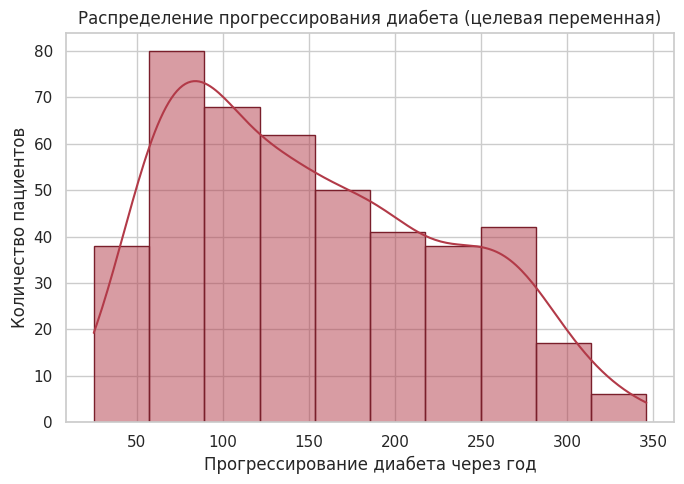

In [7]:
plt.figure(figsize=(7, 5))
sns.histplot(df["target"], kde=True, color=RED, edgecolor=RED_DARK)
plt.title("Распределение прогрессирования диабета (целевая переменная)")
plt.xlabel("Прогрессирование диабета через год")
plt.ylabel("Количество пациентов")
plt.tight_layout()
plt.show()


### 4.2. Гистограммы распределения признаков


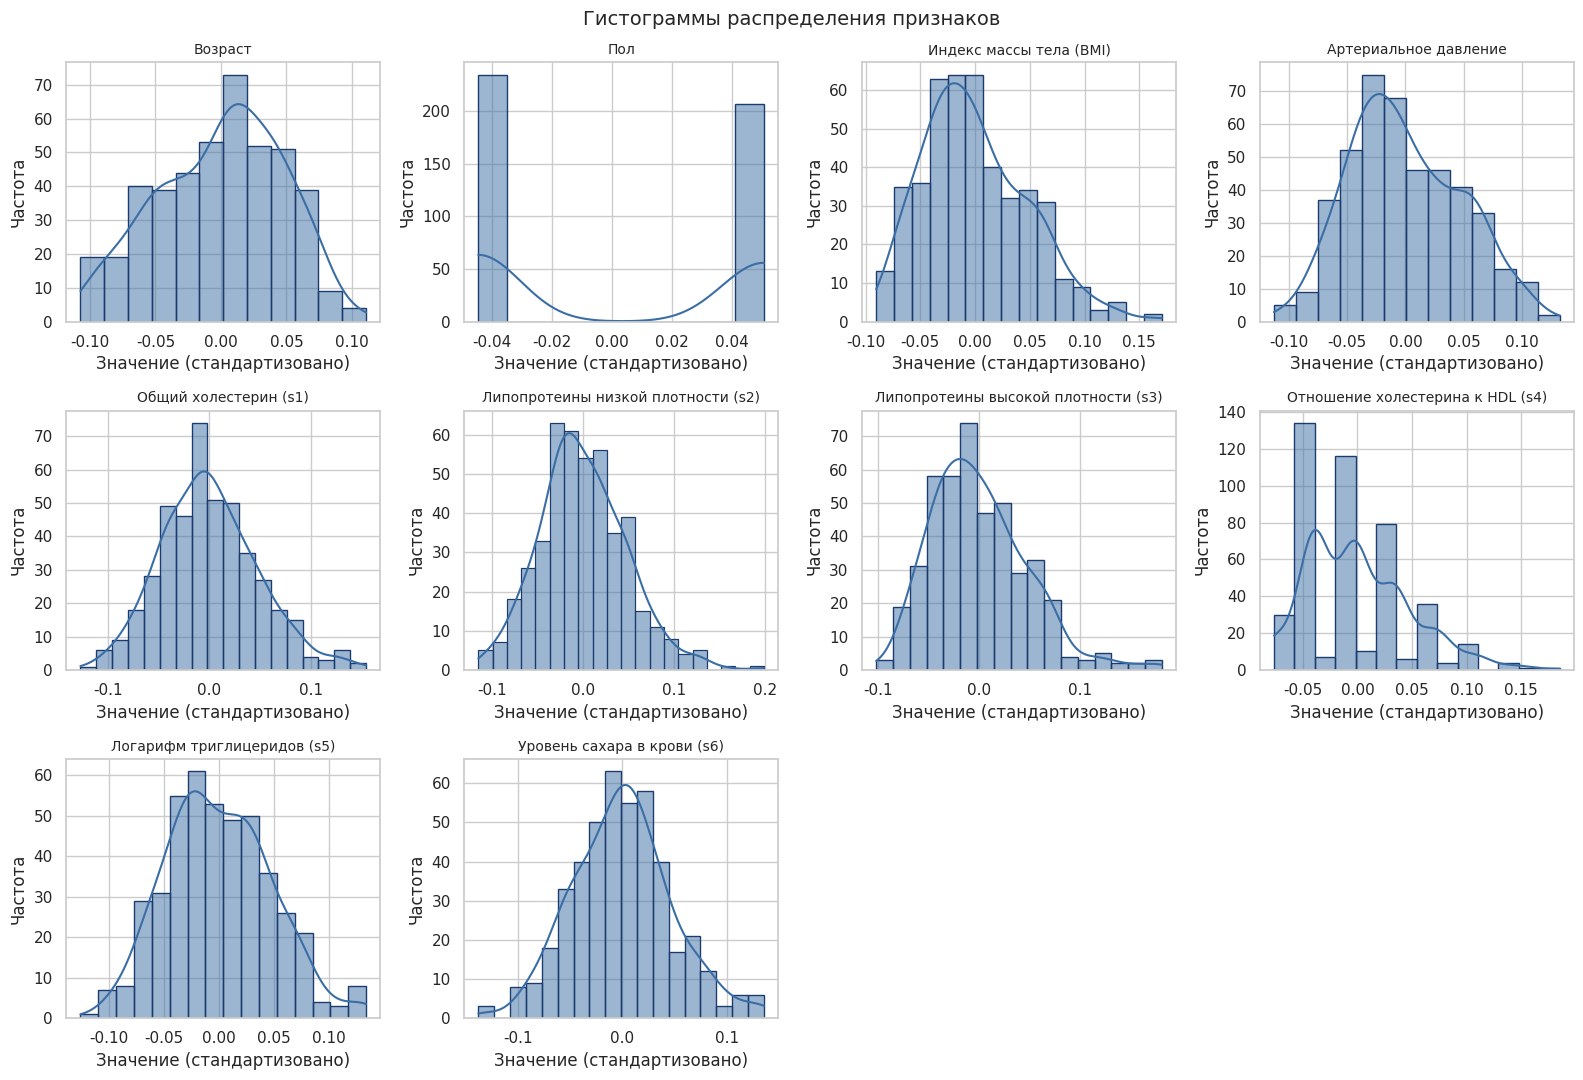

In [8]:
numeric_cols = list(data.feature_names)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color=BLUE, edgecolor=BLUE_DARK)
    axes[i].set_title(feature_names_ru[col], fontsize=10)
    axes[i].set_xlabel("Значение (стандартизовано)")
    axes[i].set_ylabel("Частота")
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
fig.suptitle("Гистограммы распределения признаков", fontsize=14)
plt.tight_layout()
plt.show()


### 4.3. Диаграммы размаха (boxplot)

Рассмотрим разброс значений ключевых признаков (`bmi`, `bp`, `s5`).


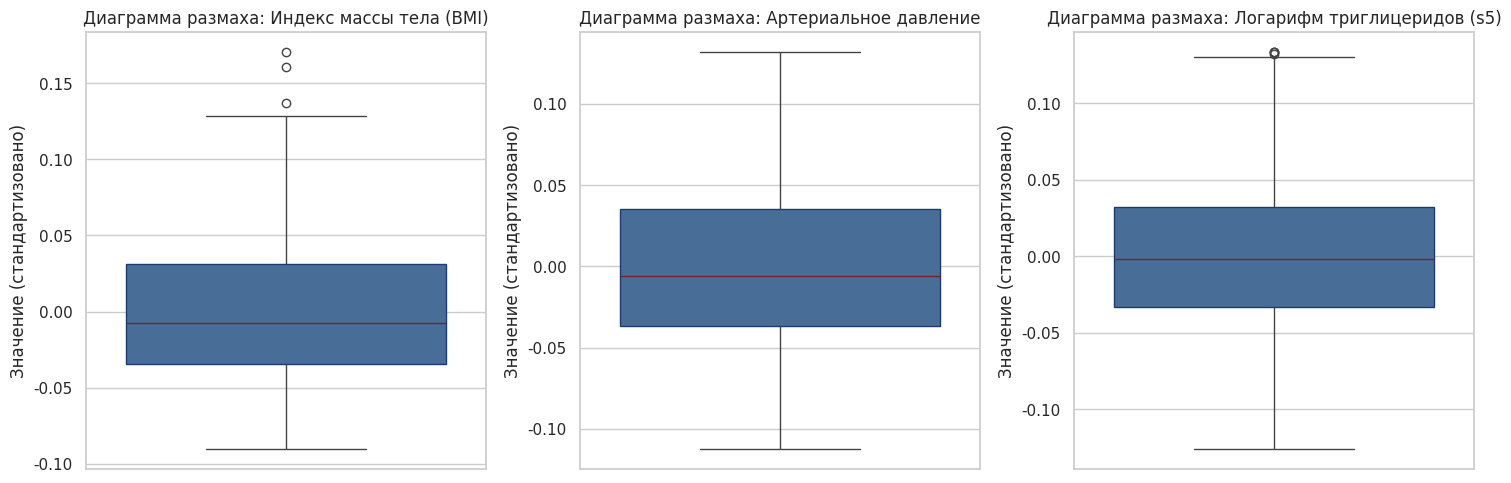

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ["bmi", "bp", "s5"]):
    sns.boxplot(y=df[col], ax=ax, color=BLUE, boxprops={"edgecolor": BLUE_DARK}, medianprops={"color": RED_DARK})
    ax.set_title(f"Диаграмма размаха: {feature_names_ru[col]}")
    ax.set_ylabel("Значение (стандартизовано)")
plt.tight_layout()
plt.show()


### 4.4. Пол пациента и прогрессирование диабета (violinplot)

В датасете признак `sex` бинарный (закодирован числовыми значениями после стандартизации). Разделим пациентов на две группы по знаку признака и сравним прогрессирование диабета.


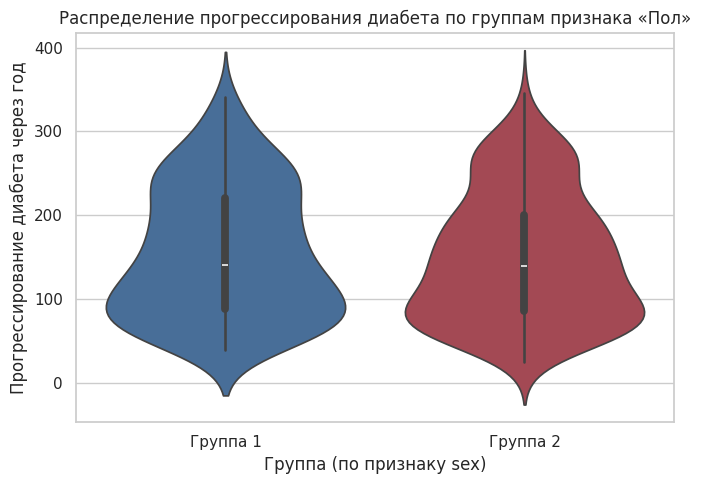

In [10]:
df["sex_group"] = np.where(df["sex"] > 0, "Группа 1", "Группа 2")

plt.figure(figsize=(7, 5))
sns.violinplot(data=df, x="sex_group", y="target", hue="sex_group", palette=PALETTE_2, legend=False)
plt.title("Распределение прогрессирования диабета по группам признака «Пол»")
plt.xlabel("Группа (по признаку sex)")
plt.ylabel("Прогрессирование диабета через год")
plt.tight_layout()
plt.show()


### 4.5. Диаграммы рассеяния


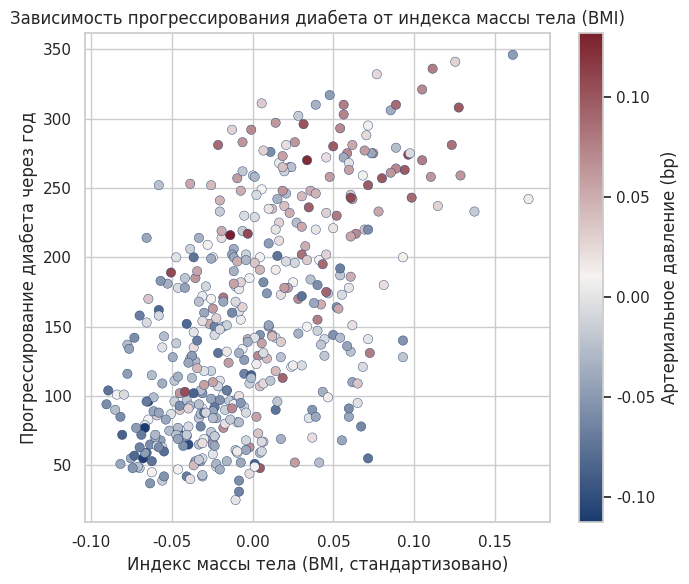

In [11]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(df["bmi"], df["target"], c=df["bp"], cmap=CMAP_DIVERGING, s=45, edgecolor=BLUE_DARK, linewidth=0.3)
cbar = plt.colorbar(sc)
cbar.set_label("Артериальное давление (bp)")
plt.title("Зависимость прогрессирования диабета от индекса массы тела (BMI)")
plt.xlabel("Индекс массы тела (BMI, стандартизовано)")
plt.ylabel("Прогрессирование диабета через год")
plt.tight_layout()
plt.show()


### 4.6. Попарные диаграммы рассеяния (pairplot)

Возьмём подмножество наиболее информативных признаков и целевую переменную.


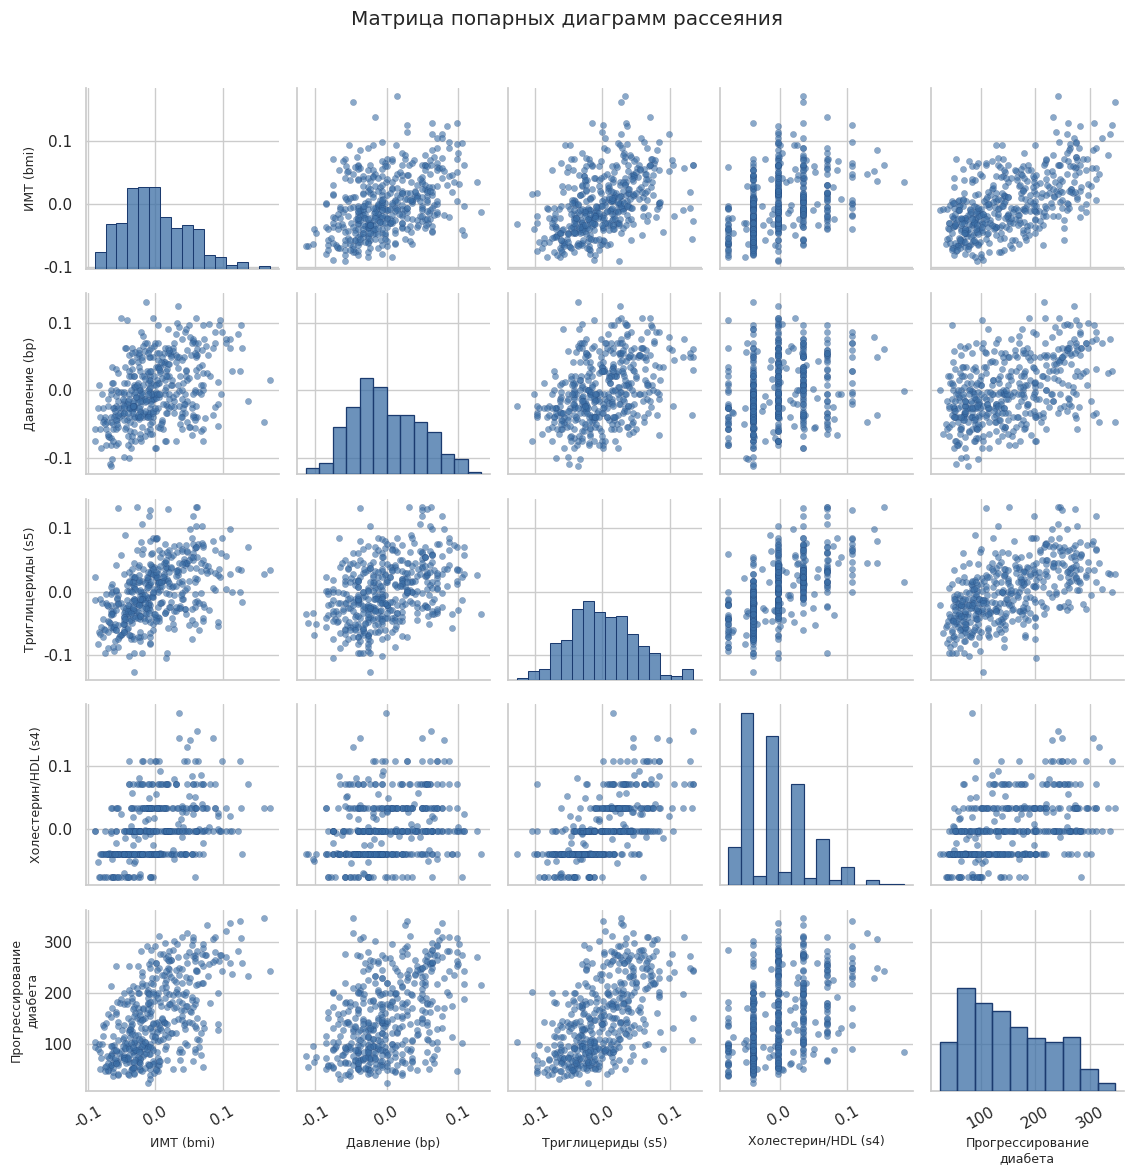

In [12]:
subset_cols = ["bmi", "bp", "s5", "s4", "target"]
subset_titles_short = {
    "bmi": "ИМТ (bmi)",
    "bp": "Давление (bp)",
    "s5": "Триглицериды (s5)",
    "s4": "Холестерин/HDL (s4)",
    "target": "Прогрессирование\nдиабета",
}

g = sns.pairplot(
    df[subset_cols], diag_kind="hist", height=2.3,
    plot_kws={"s": 20, "alpha": 0.6, "color": BLUE, "edgecolor": BLUE_DARK, "linewidth": 0.2},
    diag_kws={"color": BLUE, "edgecolor": BLUE_DARK},
)
for ax in g.axes.flatten():
    if ax is not None:
        xl, yl = ax.get_xlabel(), ax.get_ylabel()
        if xl in subset_titles_short:
            ax.set_xlabel(subset_titles_short[xl], fontsize=9)
        if yl in subset_titles_short:
            ax.set_ylabel(subset_titles_short[yl], fontsize=9)
        ax.tick_params(axis="x", labelrotation=30)
g.fig.suptitle("Матрица попарных диаграмм рассеяния", y=1.02)
plt.tight_layout()
plt.show()


## 5. Анализ корреляции признаков


In [13]:
corr_cols = numeric_cols + ["target"]
corr = df[corr_cols].corr()
corr_display = corr.rename(index=feature_names_ru, columns=feature_names_ru)
corr_display.round(2)


,Возраст,Пол,Индекс массы тела (BMI),Артериальное давление,Общий холестерин (s1),Липопротеины низкой плотности (s2),Липопротеины высокой плотности (s3),Отношение холестерина к HDL (s4),Логарифм триглицеридов (s5),Уровень сахара в крови (s6),Прогрессирование диабета (целевая переменная)
Возраст,1.00,0.17,0.19,0.34,0.26,0.22,-0.08,0.20,0.27,0.30,0.19
Пол,0.17,1.00,0.09,0.24,0.04,0.14,-0.38,0.33,0.15,0.21,0.04
Индекс массы тела (BMI),0.19,0.09,1.00,0.40,0.25,0.26,-0.37,0.41,0.45,0.39,0.59
Артериальное давление,0.34,0.24,0.40,1.00,0.24,0.19,-0.18,0.26,0.39,0.39,0.44
Общий холестерин (s1),0.26,0.04,0.25,0.24,1.00,0.90,0.05,0.54,0.52,0.33,0.21
Липопротеины низкой плотности (s2),0.22,0.14,0.26,0.19,0.90,1.00,-0.20,0.66,0.32,0.29,0.17
Липопротеины высокой плотности (s3),-0.08,-0.38,-0.37,-0.18,0.05,-0.20,1.00,-0.74,-0.40,-0.27,-0.39
Отношение холестерина к HDL (s4),0.20,0.33,0.41,0.26,0.54,0.66,-0.74,1.00,0.62,0.42,0.43
Логарифм триглицеридов (s5),0.27,0.15,0.45,0.39,0.52,0.32,-0.40,0.62,1.00,0.46,0.57
Уровень сахара в крови (s6),0.30,0.21,0.39,0.39,0.33,0.29,-0.27,0.42,0.46,1.00,0.38


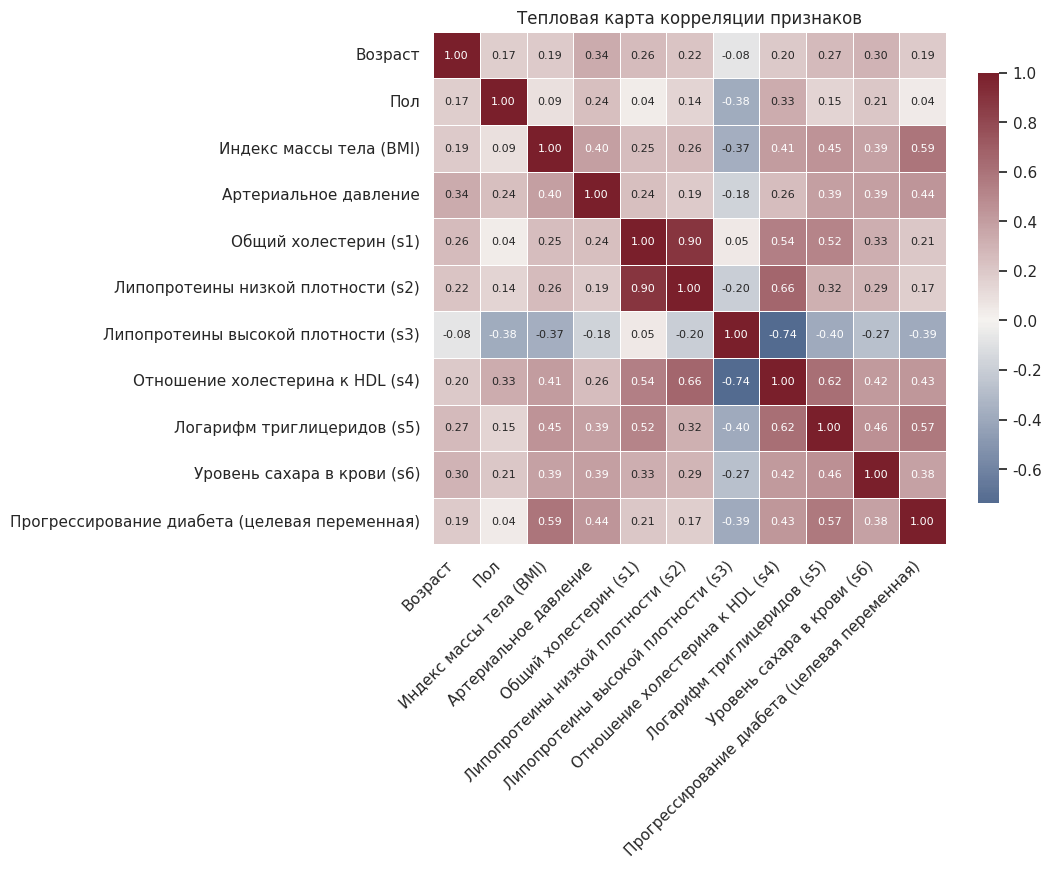

In [14]:
plt.figure(figsize=(11, 9))
sns.heatmap(corr_display, annot=True, fmt=".2f", cmap=CMAP_DIVERGING, center=0, square=True,
            cbar_kws={"shrink": 0.8}, annot_kws={"size": 8}, linewidths=0.4, linecolor="white")
plt.title("Тепловая карта корреляции признаков")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [15]:
corr_pairs = corr.where(~np.eye(corr.shape[0], dtype=bool)).unstack().dropna()
corr_pairs = corr_pairs[corr_pairs.index.map(lambda x: x[0] < x[1])]
top_corr = corr_pairs.abs().sort_values(ascending=False).head(10)
print("Топ-10 пар признаков по модулю коэффициента корреляции:")
for (f1, f2), _ in top_corr.items():
    print(f"{feature_names_ru[f1]:45s} - {feature_names_ru[f2]:45s} : r = {corr.loc[f1, f2]: .3f}")


Топ-10 пар признаков по модулю коэффициента корреляции:
Общий холестерин (s1)                         - Липопротеины низкой плотности (s2)            : r =  0.897
Липопротеины высокой плотности (s3)           - Отношение холестерина к HDL (s4)              : r = -0.738
Липопротеины низкой плотности (s2)            - Отношение холестерина к HDL (s4)              : r =  0.660
Отношение холестерина к HDL (s4)              - Логарифм триглицеридов (s5)                   : r =  0.618
Индекс массы тела (BMI)                       - Прогрессирование диабета (целевая переменная) : r =  0.586
Логарифм триглицеридов (s5)                   - Прогрессирование диабета (целевая переменная) : r =  0.566
Общий холестерин (s1)                         - Отношение холестерина к HDL (s4)              : r =  0.542
Общий холестерин (s1)                         - Логарифм триглицеридов (s5)                   : r =  0.516
Логарифм триглицеридов (s5)                   - Уровень сахара в крови (s6)             

### 5.1. Диаграмма рассеяния для признака, наиболее коррелированного с целевой переменной


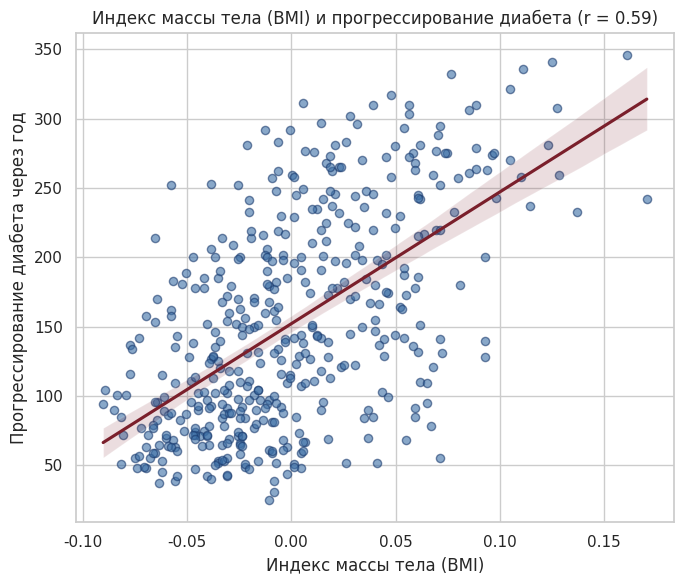

In [16]:
target_corr = corr["target"].drop("target").abs().sort_values(ascending=False)
best_feature = target_corr.index[0]

plt.figure(figsize=(7, 6))
sns.regplot(data=df, x=best_feature, y="target",
            scatter_kws={"s": 35, "alpha": 0.6, "color": BLUE, "edgecolor": BLUE_DARK},
            line_kws={"color": RED_DARK})
r_value = corr.loc[best_feature, "target"]
plt.title(f"{feature_names_ru[best_feature]} и прогрессирование диабета (r = {r_value:.2f})")
plt.xlabel(feature_names_ru[best_feature])
plt.ylabel("Прогрессирование диабета через год")
plt.tight_layout()
plt.show()


## 6. Выводы

1. Набор данных `diabetes` состоит из 442 наблюдений и 10 числовых признаков, пропущенные значения отсутствуют, все признаки предварительно стандартизованы.
2. Наибольшую положительную корреляцию с прогрессированием диабета (целевой переменной) демонстрируют признаки `bmi` (индекс массы тела) и `s5` (логарифм уровня триглицеридов), что согласуется с медицинскими представлениями о факторах риска диабета.
3. Признак `bp` (артериальное давление) также заметно связан с целевой переменной и с рядом других признаков (например, с `bmi`), что говорит о наличии мультиколлинеарности между некоторыми предикторами.
4. Распределения признаков в целом близки к нормальным (что ожидаемо, так как данные стандартизованы), выраженных выбросов не выявлено.
5. Проведённый разведочный анализ данных с использованием гистограмм, boxplot, violinplot, scatterplot, pairplot и тепловой карты корреляции позволил получить полное представление о структуре набора данных и выделить наиболее значимые признаки для дальнейшего построения моделей машинного обучения (регрессии), предсказывающих прогрессирование диабета.
